In [1]:
import numpy as np
import pandas as pd
import joblib
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

X_train = np.load('../data/processed/X_train.npy')
X_test = np.load('../data/processed/X_test.npy')
y_train = np.load('../data/processed/y_train.npy')
y_test = np.load('../data/processed/y_test.npy')

label_encoder = joblib.load('../models/label_encoder.pkl')
class_names = label_encoder.classes_

print("Classes:", class_names)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Classes: ['DoS' 'Normal' 'Probe' 'R2L' 'U2R']
Train shape: (8380225, 77) Test shape: (504160, 77)


In [2]:
results = {}

def train_and_evaluate(model, model_name):
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    start = time.time()
    y_pred = model.predict(X_test)
    predict_time = time.time() - start

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results[model_name] = {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1,
        'Train Time (s)': train_time, 'Predict Time (s)': predict_time
    }

    print(f"\n===== {model_name} =====")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    print(f"Training time: {train_time:.2f}s | Prediction time: {predict_time:.2f}s")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.savefig(f'../reports/figures/confusion_matrix_{model_name}.png')
    plt.show()

    return model


===== Decision_Tree =====
Accuracy: 0.9986 | Precision: 0.9987 | Recall: 0.9986 | F1: 0.9986
Training time: 453.18s | Prediction time: 0.18s

Classification Report:
               precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     64354
      Normal       1.00      1.00      1.00    419012
       Probe       0.99      0.99      0.99     18139
         R2L       0.90      1.00      0.95      2648
         U2R       0.71      0.71      0.71         7

    accuracy                           1.00    504160
   macro avg       0.92      0.94      0.93    504160
weighted avg       1.00      1.00      1.00    504160



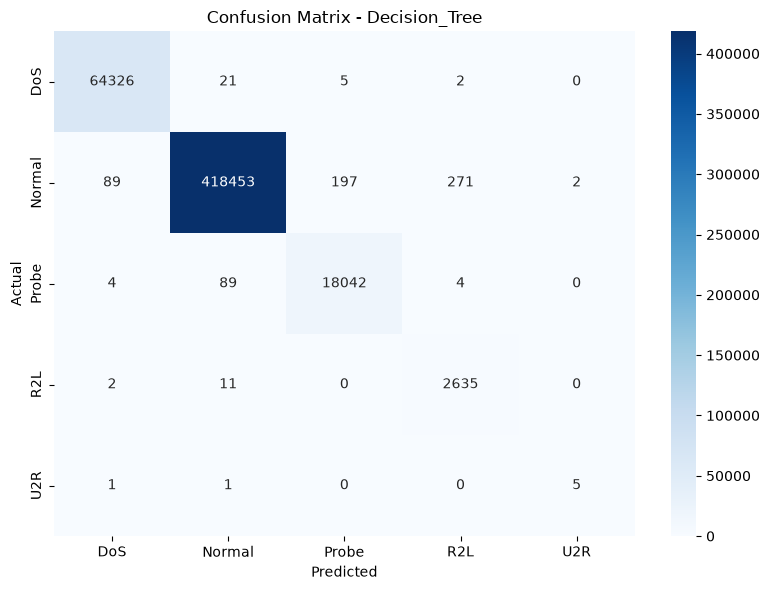

In [3]:
dt_model = DecisionTreeClassifier(random_state=42, max_depth=20)
dt_model = train_and_evaluate(dt_model, "Decision_Tree")


===== Random_Forest =====
Accuracy: 0.9981 | Precision: 0.9982 | Recall: 0.9981 | F1: 0.9981
Training time: 568.45s | Prediction time: 1.66s

Classification Report:
               precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     64354
      Normal       1.00      1.00      1.00    419012
       Probe       0.99      1.00      0.99     18139
         R2L       0.83      1.00      0.90      2648
         U2R       1.00      0.57      0.73         7

    accuracy                           1.00    504160
   macro avg       0.96      0.91      0.92    504160
weighted avg       1.00      1.00      1.00    504160



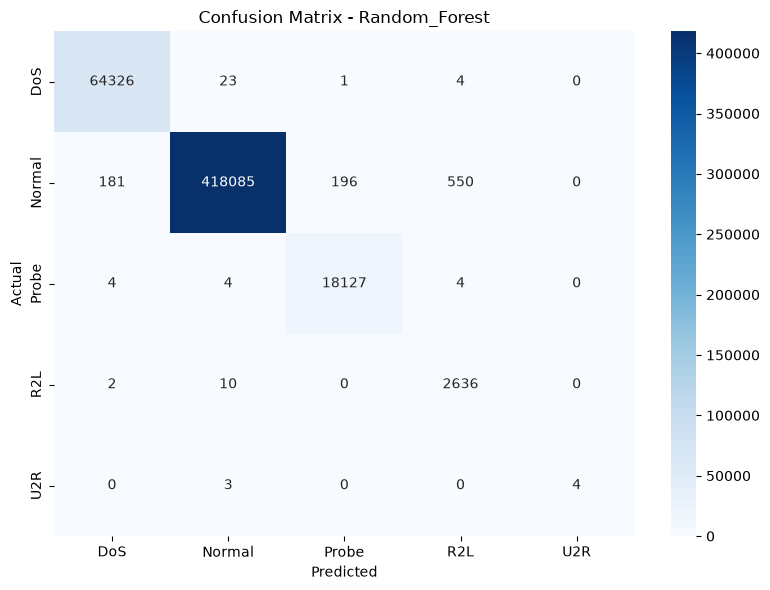

In [4]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_model = train_and_evaluate(rf_model, "Random_Forest")


===== XGBoost =====
Accuracy: 0.9985 | Precision: 0.9986 | Recall: 0.9985 | F1: 0.9985
Training time: 251.25s | Prediction time: 0.84s

Classification Report:
               precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     64354
      Normal       1.00      1.00      1.00    419012
       Probe       0.99      1.00      0.99     18139
         R2L       0.86      1.00      0.92      2648
         U2R       1.00      0.71      0.83         7

    accuracy                           1.00    504160
   macro avg       0.97      0.94      0.95    504160
weighted avg       1.00      1.00      1.00    504160



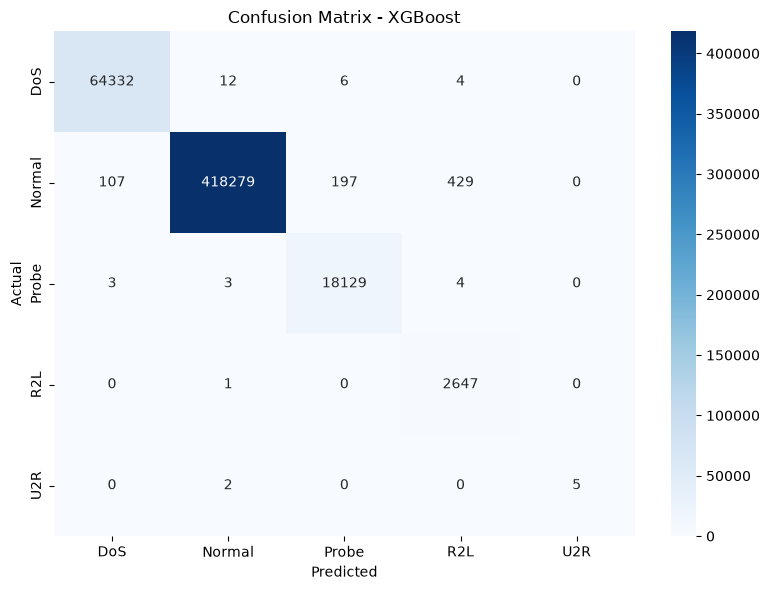

In [5]:
xgb_model = XGBClassifier(
    n_estimators=100, max_depth=8, learning_rate=0.1,
    random_state=42, eval_metric='mlogloss'
)
xgb_model = train_and_evaluate(xgb_model, "XGBoost")

In [6]:
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df.sort_values('F1-Score', ascending=False)
print(comparison_df)

comparison_df.to_csv('../reports/model_comparison.csv')

               Accuracy  Precision    Recall  F1-Score  Train Time (s)  \
Decision_Tree  0.998614   0.998666  0.998614  0.998628      453.176337   
XGBoost        0.998477   0.998604  0.998477  0.998510      251.250228   
Random_Forest  0.998052   0.998246  0.998052  0.998105      568.448596   

               Predict Time (s)  
Decision_Tree          0.179321  
XGBoost                0.843816  
Random_Forest          1.662518  


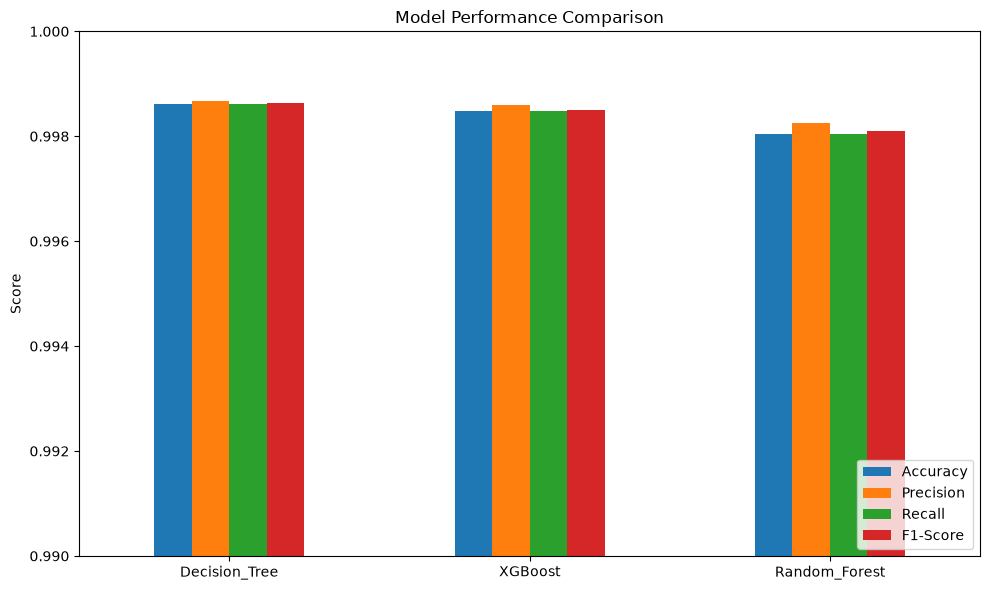

In [7]:
comparison_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', figsize=(10,6))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0.99, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../reports/figures/model_comparison_bar.png')
plt.show()

In [8]:
best_model_name = comparison_df['F1-Score'].idxmax()
print(f"Best model (by weighted F1): {best_model_name}")

model_dict = {'Decision_Tree': dt_model, 'Random_Forest': rf_model, 'XGBoost': xgb_model}
best_model = model_dict[best_model_name]

joblib.dump(best_model, '../models/best_model.pkl')

joblib.dump(dt_model, '../models/decision_tree_model.pkl')
joblib.dump(rf_model, '../models/random_forest_model.pkl')
joblib.dump(xgb_model, '../models/xgboost_model.pkl')

print("All models saved to /models/")

Best model (by weighted F1): Decision_Tree
All models saved to /models/
